In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATA_PATH = "/content/drive/MyDrive/NIFTY50_LSTM2.csv"
data = pd.read_csv(
    DATA_PATH
)
data.head()

,DATETIME,SYMBOL,OPEN,HIGH,LOW,CLOSE,VOLUME,PREVIOUS CLOSE
0,11-02-1997,NIFTY,998.19,999.45,987.37,993.42,33414539.0,981.45
1,12-02-1997,NIFTY,991.77,996.29,985.86,991.83,39503519.0,993.42
2,13-02-1997,NIFTY,1004.94,1016.94,998.48,1009.89,45939628.0,991.83
3,14-02-1997,NIFTY,1046.06,1055.21,1044.10,1049.84,36813234.0,1009.89
4,17-02-1997,NIFTY,1043.99,1048.92,1038.17,1045.85,48124579.0,1049.84


In [ ]:
# Remove extra spaces from column names
data.columns = data.columns.str.strip()
# Filter only NIFTY-50 records
data["SYMBOL"] = data["SYMBOL"].astype(str).str.strip()

In [ ]:
data = data[data["SYMBOL"]=="NIFTY"].copy()

In [ ]:
data = data[["DATETIME","OPEN","HIGH","LOW","CLOSE"]].copy()

In [ ]:
data.columns = ["Date","Open","High","Low","Close"]

In [ ]:
# 1. Convert date into datetime format correctly (using data["Date"])
data["Date"] = pd.to_datetime(
    data["Date"],
    dayfirst=True,
    errors="coerce"
)

# 2. Convert numerical columns correctly (using data[col])
for col in ["Open", "High", "Low", "Close"]:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

In [ ]:
data = data.sort_values(
  "Date"
).reset_index(drop=True)

In [ ]:
data.head()

,Date,Open,High,Low,Close
0,1997-02-11,998.19,999.45,987.37,993.42
1,1997-02-12,991.77,996.29,985.86,991.83
2,1997-02-13,1004.94,1016.94,998.48,1009.89
3,1997-02-14,1046.06,1055.21,1044.10,1049.84
4,1997-02-17,1043.99,1048.92,1038.17,1045.85


In [ ]:
data["Previous_Close"] = data["Close"].shift(1)
data = data.dropna().reset_index(drop=True)
data.head()

,Date,Open,High,Low,Close,Previous_Close
0,1997-02-12,991.77,996.29,985.86,991.83,993.42
1,1997-02-13,1004.94,1016.94,998.48,1009.89,991.83
2,1997-02-14,1046.06,1055.21,1044.10,1049.84,1009.89
3,1997-02-17,1043.99,1048.92,1038.17,1045.85,1049.84
4,1997-02-18,1042.68,1046.63,1038.67,1041.87,1045.85


In [ ]:
X=data[["Open","High","Low","Previous_Close"]].values
Y=data[["Close"]].values

In [ ]:
split_index=int(len(data)*0.8)
X_train = X[:split_index]
Y_train=Y[:split_index]

X_test = X[split_index:]
Y_test = Y[split_index:]

In [ ]:
from sklearn.preprocessing import MinMaxScaler
x_scale = MinMaxScaler()
y_scale = MinMaxScaler()
x_train_scaled = x_scale.fit_transform(X_train)
x_test_scaled = x_scale.transform(X_test)
y_train_scaled = y_scale.fit_transform(Y_train)

In [ ]:
x_train_scaled


array([[0.01732526, 0.01724233, 0.01727681, 0.01738399],
       [0.01850543, 0.0190805 , 0.0184124 , 0.01724108],
       [0.0221902 , 0.02248713, 0.02251745, 0.01886426],
       ...,
       [0.98452071, 0.98554475, 0.98225257, 0.987517  ],
       [0.97901864, 0.98076372, 0.97678248, 0.98376913],
       [0.95185238, 0.94830861, 0.9522521 , 0.98485754]], shape=(5597, 4))

In [ ]:
x_train_scaled = x_train_scaled.reshape(
    x_train_scaled.shape[0],1,4
)
x_test_scaled = x_test_scaled.reshape(
    x_test_scaled.shape[0],1,4
)
x_test_scaled

array([[[0.95740553, 0.95700544, 0.95565708, 0.95630814]],

       [[0.96790517, 0.96294012, 0.96533479, 0.95630814]],

       [[0.9571833 , 0.9591703 , 0.95643273, 0.96808202]],

       ...,

       [[2.09819319, 2.10108261, 2.09013098, 2.10700114]],

       [[2.10344883, 2.10054317, 2.10800888, 2.10757905]],

       [[2.11295738, 2.10193449, 2.10597256, 2.10930738]]],
      shape=(1400, 1, 4))

In [ ]:
'''from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
model = Sequential()
model.add(
    LSTM(64,input_shape=(1,4))
)
model.add(
    Dense(32,activation="relu")
)
model.add(
    Dense(1)
)
model.compile(
    optimizer = "adam",
    loss = "mean_squared_error"
)
model.summary()'''
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

model = Sequential([
    Input(shape=(1, 4)),                  # Explicit Input layer fixes the shape/rank error
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,777 (77.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    x_train_scaled,
    y_train_scaled,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0422
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.5094e-05
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 3.7593e-06
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.9567e-06
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.8007e-06
Epoch 6/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.8453e-06
Epoch 7/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 2.7900e-06
Epoch 8/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.7807e-06
Epoch 9/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.7935e-06
Epoch 10/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.7092e-06
Epoch 11/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.7655e-06
Epoch 12/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.8668e-06
Epoch 13/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2.8672e-06
Epoch 14/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 3.0134e-06
Epoch

In [ ]:
predicted_scaled = model.predict(x_test_scaled)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [ ]:
predicted_prices = y_scale.inverse_transform(predicted_scaled)
predicted_prices

array([[11489.581 ],
       [11561.4375],
       [11531.552 ],
       ...,
       [22866.527 ],
       [22918.453 ],
       [22940.338 ]], shape=(1400, 1), dtype=float32)

In [ ]:
actual_prices = Y_test

result = pd.DataFrame({
    "Actual Closing Prices": actual_prices.flatten(),
    "Predicted Closing Prices": predicted_prices.flatten()
})
result

,Actual Closing Prices,Predicted Closing Prices
0,11440.20,11489.581055
1,11571.20,11561.437500
2,11512.40,11531.551758
3,11474.45,11484.313477
4,11359.90,11414.757812
...,...,...
1395,24240.76,22845.246094
1396,24243.19,22922.455078
1397,24249.62,22866.527344
1398,24268.85,22918.453125


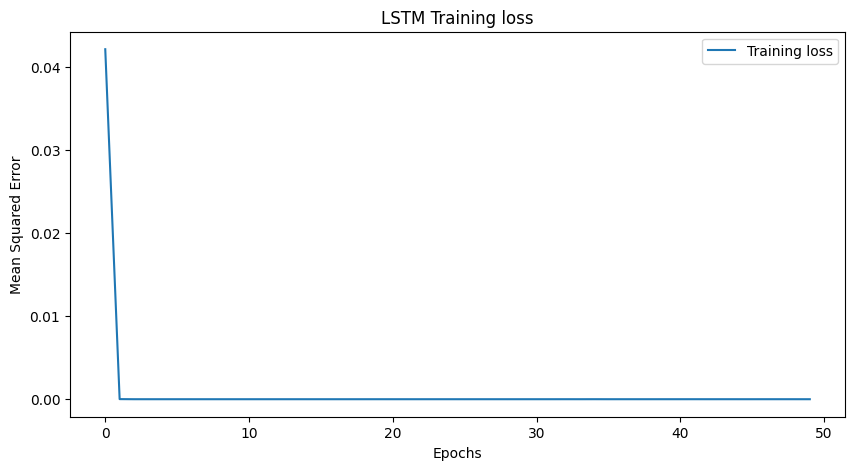

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(
    history.history["loss"],
    label="Training loss"
)
plt.title("LSTM Training loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()


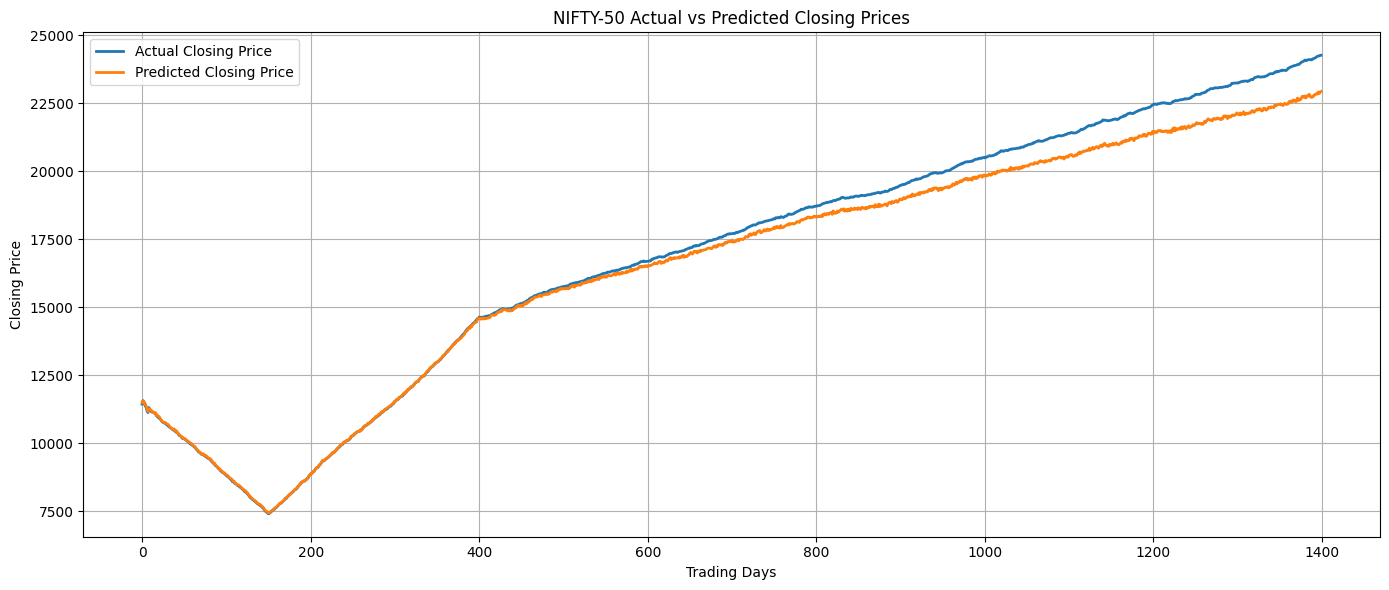

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(
actual_prices,
label="Actual Closing Price",
linewidth=2
)
plt.plot(
predicted_prices,
label="Predicted Closing Price",
linewidth=2
)
plt.title("NIFTY-50 Actual vs Predicted Closing Prices")
plt.xlabel("Trading Days")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()